# Analisis dan Visualisasi Time Series Cuaca Harian Kota Bandung (2016–2026)

**Midterm Project – CAK4XBB3 Visualisasi Data**

| | |
|---|---|
| **Anggota** | Muhammad Regian Yogaswara - 103012300478 <br> Najma Qhistinaya - 103012330086 <br> Hilma Aulia - 103012300287 <br> Amira Kamila Arvina - 103012340061 <br> Maliki Kadafa Tsaqif - 103012340185 |
| **Program Studi** | [S1 Informatika] |

---

## 1. Pendahuluan

**Topik.** Tren suhu, curah hujan, dan sinar matahari harian di Kota Bandung selama hampir 11 tahun (1 Januari 2016 – 31 Oktober 2026).

**Mengapa menarik?** Bandung berada di dataran tinggi (±810 m di atas laut), jadi udaranya relatif sejuk dibanding kota pesisir. Pola cuacanya (musim hujan/kemarau, malam yang dingin saat kemarau) berpengaruh langsung ke kehidupan sehari-hari: aktivitas luar ruangan, pertanian di sekitar Bandung, sampai risiko banjir saat hujan lebat.

**Pertanyaan yang ingin dijawab dari data:**
1. Seperti apa pola suhu harian Bandung dari tahun ke tahun, dan apakah ada bulan/tahun yang ekstrem?
2. Kapan musim hujan dan musim kemarau terjadi, dan seberapa konsisten polanya tiap tahun?
3. Bagaimana hubungan suhu maksimum, rata-rata, dan minimum satu sama lain?
4. Apakah ada tren naik atau turun dalam suhu selama periode 2016–2026?
5. Bagaimana pengaruh ukuran window *moving average* terhadap kehalusan kurva?

## 2. Dataset

| Keterangan | Isi |
|---|---|
| **Nama dataset** | Dataset Cuaca Harian Bandung (`Dataset_Bandung_jan_2016_-_sep_2026.csv`) |
| **Sumber** | Open-Meteo Historical Weather API — https://open-meteo.com/en/docs/historical-weather-api *(format kolom file cocok dengan keluaran Open-Meteo; pastikan tautan sumber ini sesuai dengan cara kelompok mengunduhnya)* |
| **Lokasi** | Lat −6.9244, Lon 107.6054, elevasi 810 m, zona waktu Asia/Jakarta (GMT+7) |
| **Granularitas waktu** | Harian |
| **Jumlah observasi** | 3.957 hari (1 Jan 2016 – 31 Okt 2026) |
| **Variabel** | Suhu rata-rata, maksimum, minimum (°C); total curah hujan (mm); durasi sinar matahari (detik → jam); kecepatan angin maksimum (km/jam) |

## Daftar Isi
1. Pendahuluan & Dataset
2. Persiapan (import library, memuat & membersihkan data)
3. Visualisasi wajib: Line Plot, Area Plot, Multiple Time Series, Seasonal Plot & Heatmap
4. Analisis Tren: Moving Average & Fitting Model
5. Ringkasan Insight, Kesimpulan
6. Deklarasi Penggunaan AI & Daftar Pustaka

## 3. Persiapan Data

### 3.1 Import library

In [16]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
print("Library siap dipakai.")

Library siap dipakai.


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Menyiapkan 'alat-alat' yang dipakai di seluruh notebook: `pandas` & `numpy` untuk mengolah data, `matplotlib` & `seaborn` untuk membuat grafik.
>
> **Ngapain di cell ini?** Meng-import library, mengatur tema grafik supaya seragam (latar putih bergaris, ukuran judul, tanpa garis tepi atas/kanan), dan membuat daftar nama bulan singkat berbahasa Indonesia untuk label sumbu.
>
> **Insight / hasilnya:** Tidak ada grafik di sini. Output `Library siap dipakai.` menandakan semua library berhasil dimuat tanpa error.

### 3.2 Memuat data (load dataset)

In [17]:
NAMA_FILE = "Dataset_Bandung_jan_2016_-_sep_2026.csv"

# Cari file di beberapa lokasi umum (lokal, Google Colab, folder data)
kandidat = [NAMA_FILE, "/content/" + NAMA_FILE, "data/" + NAMA_FILE, "/mnt/user-data/uploads/" + NAMA_FILE]
path = next((p for p in kandidat if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f"File {NAMA_FILE} tidak ditemukan. Taruh di folder yang sama dengan notebook ini.")

# Baris 1-2 file berisi metadata lokasi, baris data sebenarnya dimulai dari header "time,..."
with open(path, encoding="utf-8-sig") as f:
    baris = f.read().splitlines()
idx_header = next(i for i, b in enumerate(baris) if b.startswith("time,"))

meta = pd.read_csv(path, nrows=1)
print("Metadata lokasi:")
print(f"  Latitude  : {meta.loc[0, 'latitude']}")
print(f"  Longitude : {meta.loc[0, 'longitude']}")
print(f"  Elevasi   : {meta.loc[0, 'elevation']} m")
print(f"  Zona waktu: {meta.loc[0, 'timezone']}")

raw = pd.read_csv(path, skiprows=idx_header)
print("\nUkuran data mentah:", raw.shape)
raw.head()

Metadata lokasi:
  Latitude  : -6.9244285
  Longitude : 107.60539
  Elevasi   : 810 m
  Zona waktu: Asia/Jakarta

Ukuran data mentah: (3957, 7)


,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),sunshine_duration (s),wind_speed_10m_max (km/h)
0,1/1/2016,22.7,26.0,20.8,34.0,30469.88,4.4
1,1/2/2016,22.3,25.8,20.5,20.9,25517.84,4.3
2,1/3/2016,22.6,26.9,20.2,30.9,26104.01,5.2
3,1/4/2016,22.8,25.8,20.6,18.4,22191.15,5.4
4,1/5/2016,22.7,25.1,21.2,10.3,25842.78,4.8


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Membaca file CSV ke dalam tabel pandas (DataFrame) supaya bisa dianalisis.
>
> **Ngapain di cell ini?** File CSV ini punya 'kepala' khusus: 2 baris pertama berisi metadata lokasi, lalu baris kosong, baru tabel datanya. Jadi kode mencari sendiri baris header `time,...` agar tabel terbaca benar, lalu menampilkan metadata lokasi dan 5 baris pertama data.
>
> **Insight / hasilnya:** Lokasi data adalah Bandung (lat −6,92; lon 107,61; elevasi 810 m; zona waktu Asia/Jakarta). Data mentah berukuran **3.957 baris × 7 kolom**: 1 kolom tanggal dan 6 variabel cuaca. Pada 5 baris awal (1–5 Januari 2016) terlihat suhu rata-rata ±22–23 °C dan hujan cukup banyak (10–35 mm per hari).

### 3.3 Pembersihan & pengecekan kualitas data

In [18]:
df = raw.iloc[:, :7].copy()
df.columns = ["tanggal", "suhu_rata", "suhu_maks", "suhu_min", "hujan", "sinar_detik", "angin_maks"]

# Ubah teks tanggal menjadi tipe datetime lalu jadikan index (urut kronologis)
df["tanggal"] = pd.to_datetime(df["tanggal"], format="%m/%d/%Y")
df = df.sort_values("tanggal").set_index("tanggal")

# Durasi sinar matahari: detik -> jam supaya mudah dibaca
df["sinar_jam"] = df["sinar_detik"] / 3600
df = df.drop(columns="sinar_detik")

print("Periode data      :", df.index.min().date(), "s.d.", df.index.max().date())
print("Jumlah observasi  :", len(df), "hari")
print("Tanggal terlewat  :", len(pd.date_range(df.index.min(), df.index.max())) - len(df))
print("Total nilai kosong:", int(df.isna().sum().sum()))
print("Tanggal duplikat  :", int(df.index.duplicated().sum()))
df.describe().round(2)

Periode data      : 2016-01-01 s.d. 2026-10-31
Jumlah observasi  : 3957 hari
Tanggal terlewat  : 0
Total nilai kosong: 0
Tanggal duplikat  : 0


,suhu_rata,suhu_maks,suhu_min,hujan,angin_maks,sinar_jam
count,3957.00,3957.00,3957.00,3957.00,3957.00,3957.00
mean,22.31,27.21,18.33,6.02,11.35,9.42
std,0.86,1.84,1.43,9.46,3.55,2.58
min,19.00,21.20,12.90,0.00,2.90,0.00
25%,21.80,26.00,17.50,0.40,9.00,8.00
50%,22.20,27.10,18.50,2.10,10.90,10.36
75%,22.80,28.20,19.40,7.80,13.40,11.48
max,26.90,34.20,21.70,96.70,26.70,12.25


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Memastikan data siap dianalisis: kolom bernama jelas, tanggal bertipe tanggal sungguhan, urut kronologis, dan tidak ada data hilang/ganda. Ini syarat wajib time series.
>
> **Ngapain di cell ini?** Mengganti nama kolom jadi singkat dan jelas, mengubah teks tanggal jadi `datetime` lalu dijadikan index, mengubah durasi sinar matahari dari detik ke jam, kemudian mengecek periode, jumlah baris, tanggal yang terlewat, nilai kosong, dan duplikat. Terakhir menampilkan statistik ringkas.
>
> **Insight / hasilnya:** Data **bersih dan lengkap**: 3.957 hari berurutan tanpa tanggal terlewat, tanpa nilai kosong, tanpa duplikat. Statistik ringkas: suhu rata-rata ±22,3 °C dengan variasi kecil (std 0,86 °C; rentang 19,0–26,9 °C), suhu maksimum 21,2–34,2 °C, suhu minimum 12,9–21,7 °C. Hujan rata-rata 6 mm/hari tapi bisa mencapai 96,7 mm dalam sehari. Sinar matahari rata-rata 9,4 jam/hari.

### 3.4 Agregasi bulanan & pola per bulan kalender

In [19]:
# Agregasi bulanan: suhu = rata-rata, hujan = total, sinar & angin = rata-rata
bulanan = df.resample("MS").agg({
    "suhu_rata": "mean", "suhu_maks": "mean", "suhu_min": "mean",
    "hujan": "sum", "sinar_jam": "mean", "angin_maks": "mean",
})
bulanan["tahun"] = bulanan.index.year
bulanan["bulan"] = bulanan.index.month

print("Jumlah bulan:", len(bulanan))
print("\nRata-rata per bulan kalender (klimatologi 2016-2026):")
klim = bulanan.groupby("bulan")[["suhu_rata", "suhu_maks", "suhu_min", "hujan", "sinar_jam"]].mean().round(1)
klim.index = NAMA_BULAN
klim

Jumlah bulan: 130

Rata-rata per bulan kalender (klimatologi 2016-2026):


,suhu_rata,suhu_maks,suhu_min,hujan,sinar_jam
Jan,21.9,25.7,19.1,226.3,7.7
Feb,21.9,25.6,19.0,241.9,7.6
Mar,22.2,26.5,18.8,243.8,8.7
Apr,22.3,26.9,18.6,235.3,9.2
Mei,22.5,27.2,18.5,181.0,9.9
Jun,22.1,27.2,17.7,88.2,10.4
Jul,21.8,27.5,16.9,59.2,11.0
Agu,22.4,28.5,17.2,69.1,11.4
Sep,22.8,28.9,17.7,128.8,10.7
Okt,23.1,28.8,18.6,208.0,9.8


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Data harian itu sangat 'ramai', jadi untuk melihat pola besar kita rangkum per bulan. Tabel per bulan kalender juga memperlihatkan 'wajah' rata-rata tiap bulan.
>
> **Ngapain di cell ini?** Membuat tabel `bulanan` (suhu = rata-rata bulan itu, hujan = jumlah total hujan bulan itu), lalu menghitung rata-rata tiap bulan Januari–Desember selama 2016–2026. Tabel ini dipakai di hampir semua grafik berikutnya.
>
> **Insight / hasilnya:** Ada 130 bulan data. Bulan **terbasah** rata-rata adalah **November (±303 mm)** dan yang **terkering Juli (±59 mm)**. Suhu rata-rata tertinggi di **Oktober (23,1 °C)**, suhu maksimum tertinggi di **September (28,9 °C)**, dan suhu minimum terendah di **Juli (16,9 °C)**. Sinar matahari terlama di Agustus (11,4 jam/hari) dan tersingkat di Februari (7,6 jam/hari). Jadi musim kemarau (Jun–Agu) = siang lebih panas, malam lebih dingin, langit cerah.

## 4. Visualisasi Time Series

### 4.1 Line Plot — pola suhu rata-rata sepanjang waktu

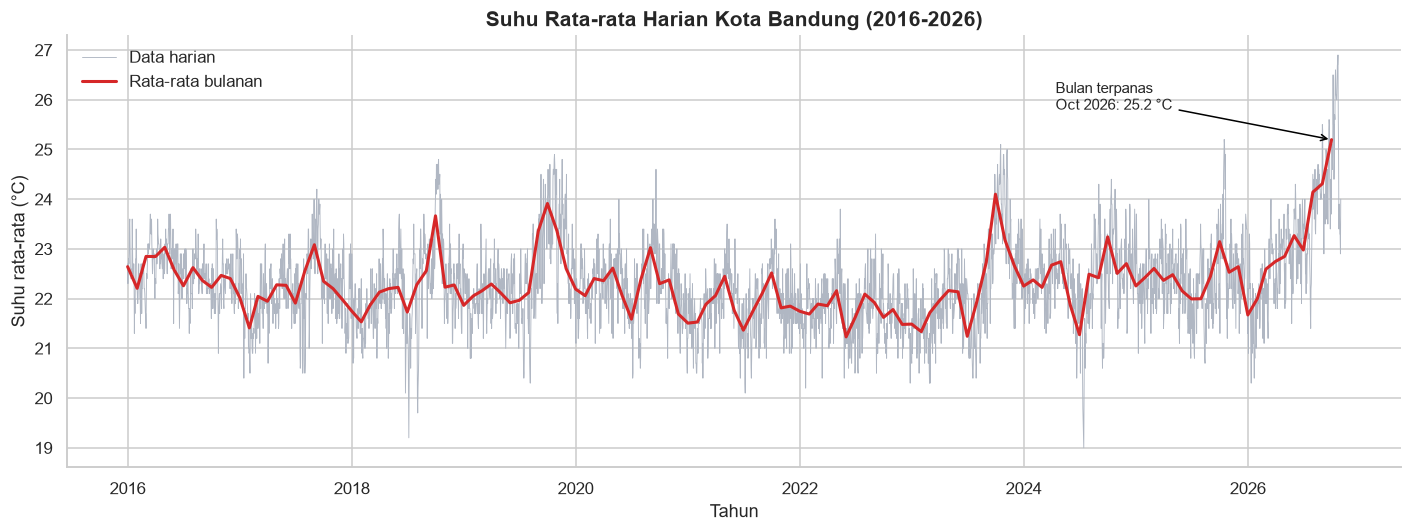

In [20]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(df.index, df["suhu_rata"], color="#b0b7c3", lw=0.6, label="Data harian")
ax.plot(bulanan.index, bulanan["suhu_rata"], color="#d62728", lw=2, label="Rata-rata bulanan")

# Tandai bulan terpanas
bln_panas = bulanan["suhu_rata"].idxmax()
ax.annotate(f"Bulan terpanas\n{bln_panas:%b %Y}: {bulanan['suhu_rata'].max():.1f} °C",
            xy=(bln_panas, bulanan["suhu_rata"].max()),
            xytext=(bln_panas - pd.Timedelta(days=900), 25.8),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)

ax.set_title("Suhu Rata-rata Harian Kota Bandung (2016-2026)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Suhu rata-rata (°C)")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Line plot adalah grafik paling dasar untuk time series: menunjukkan bagaimana satu variabel (di sini suhu rata-rata) bergerak dari waktu ke waktu.
>
> **Ngapain di cell ini?** Menggambar suhu rata-rata harian (garis abu-abu tipis, supaya terlihat detailnya) lalu menimpanya dengan rata-rata bulanan (garis merah tebal supaya polanya mudah dibaca). Bulan terpanas diberi anotasi panah.
>
> **Insight / hasilnya:** Suhu Bandung **sangat stabil**: hampir selalu bergerak di sekitar 21,5–23 °C, dan tiap tahun muncul puncak kecil sekitar September–Oktober. Beberapa tahun puncaknya lebih tinggi (2019 ±23,9 °C dan 2023 ±24,1 °C). Yang paling mencolok: **di tahun 2026 suhu terus naik dan mencapai rekor bulanan 25,2 °C pada Oktober 2026**, jauh di atas pola biasanya. (Catatan: 2026 baru sampai Oktober.)

### 4.2 Area Plot — volume/akumulasi curah hujan

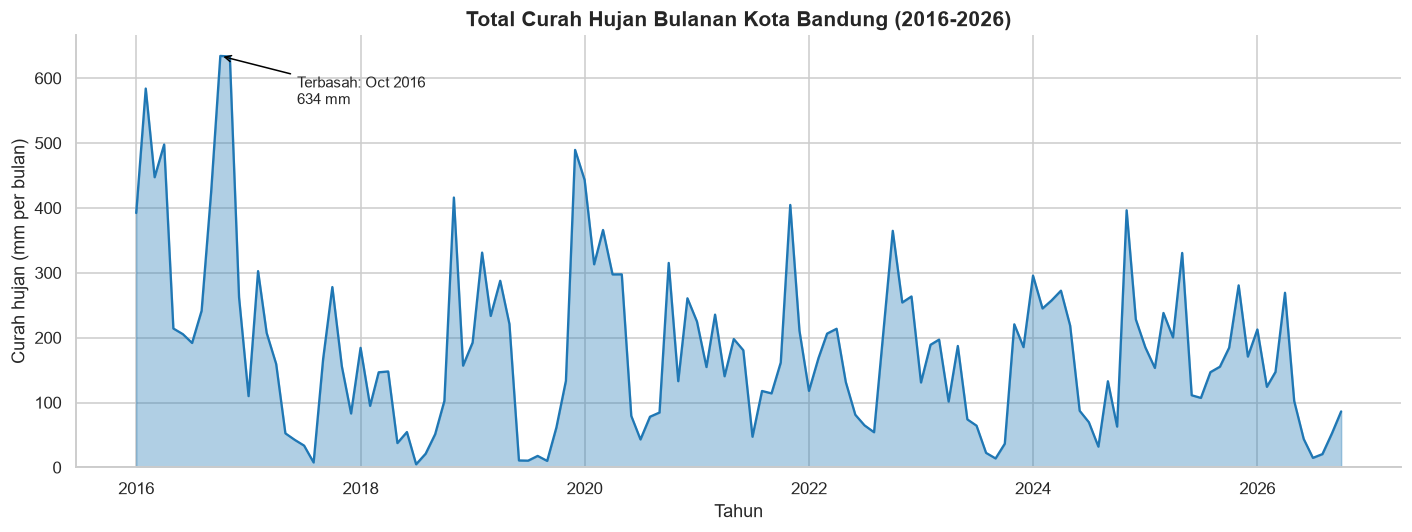

In [21]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.fill_between(bulanan.index, bulanan["hujan"], color="#1f77b4", alpha=0.35)
ax.plot(bulanan.index, bulanan["hujan"], color="#1f77b4", lw=1.5)

bln_basah = bulanan["hujan"].idxmax()
ax.annotate(f"Terbasah: {bln_basah:%b %Y}\n{bulanan['hujan'].max():.0f} mm",
            xy=(bln_basah, bulanan["hujan"].max()),
            xytext=(bln_basah + pd.Timedelta(days=250), 560),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)

ax.set_title("Total Curah Hujan Bulanan Kota Bandung (2016-2026)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Curah hujan (mm per bulan)")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Area plot menekankan *volume atau akumulasi*. Karena curah hujan adalah jumlah air yang menumpuk selama satu bulan, area plot cocok: luas daerah berwarna menggambarkan 'banyaknya hujan'.
>
> **Ngapain di cell ini?** Menghitung total hujan per bulan, lalu mengisi area di bawah garisnya dengan warna biru. Bulan dengan hujan tertinggi diberi anotasi.
>
> **Insight / hasilnya:** Terlihat pola **gelombang tahunan**: lembah dalam saat kemarau (hampir kering), puncak tinggi saat musim hujan. Bulan terbasah adalah **Oktober 2016 (634 mm)**, sedangkan terkering **Juli 2018 (hanya 4,8 mm)**. Tahun **2016 menonjol sangat basah** (±4.728 mm setahun, sementara tahun lain berkisar 1.418–2.711 mm). Kemarau 2017–2018 juga tampak sangat kering dan panjang.

### 4.3 Multiple Time Series — suhu maksimum, rata-rata, dan minimum (dengan direct labeling)

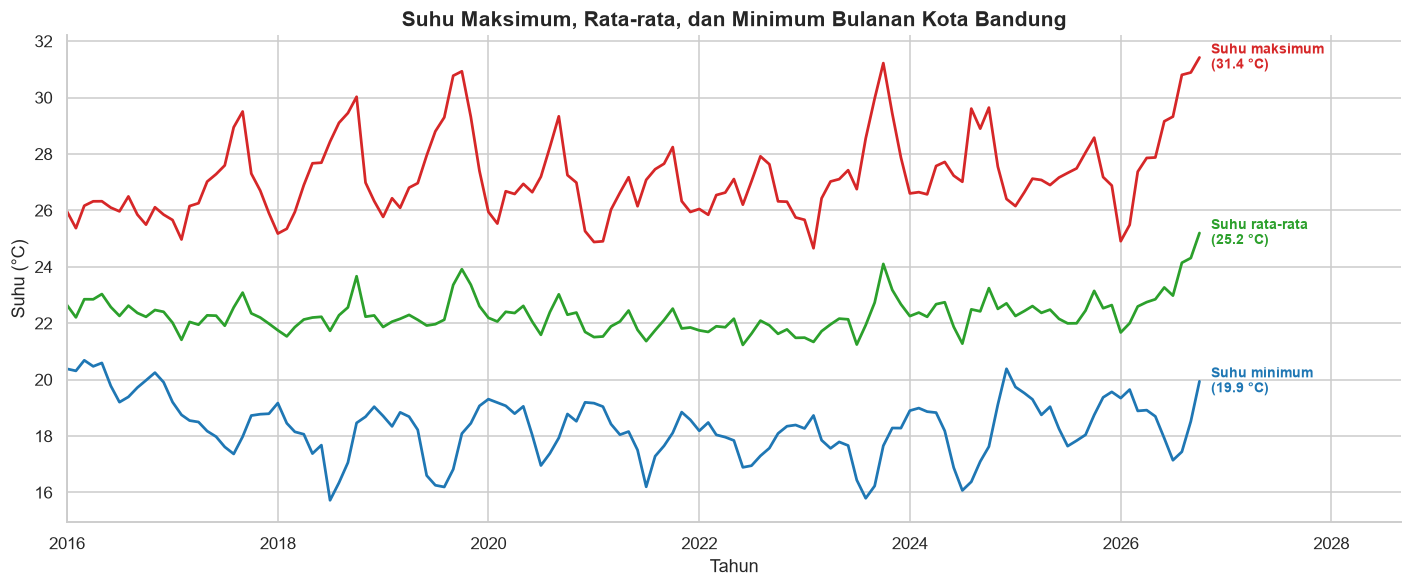

In [22]:
seri = {
    "Suhu maksimum": ("suhu_maks", "#d62728"),
    "Suhu rata-rata": ("suhu_rata", "#2ca02c"),
    "Suhu minimum": ("suhu_min", "#1f77b4"),
}

fig, ax = plt.subplots(figsize=(13, 5.5))
for nama, (kol, warna) in seri.items():
    ax.plot(bulanan.index, bulanan[kol], color=warna, lw=1.8)
    # Direct labeling: nama seri ditulis di ujung kanan garis (tanpa legend)
    ax.text(bulanan.index[-1] + pd.Timedelta(days=40), bulanan[kol].iloc[-1],
            f"{nama}\n({bulanan[kol].iloc[-1]:.1f} °C)", color=warna,
            va="center", fontsize=9, fontweight="bold")

ax.set_xlim(bulanan.index[0], bulanan.index[-1] + pd.Timedelta(days=700))
ax.set_title("Suhu Maksimum, Rata-rata, dan Minimum Bulanan Kota Bandung")
ax.set_xlabel("Tahun")
ax.set_ylabel("Suhu (°C)")
plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Membandingkan beberapa series dalam satu grafik supaya hubungan antar-variabel terlihat. Sesuai ketentuan tugas, nama series ditulis langsung di ujung garis (*direct labeling*), bukan lewat legend, supaya mata tidak bolak-balik.
>
> **Ngapain di cell ini?** Menggambar tiga garis suhu bulanan dengan warna berbeda, lalu menaruh teks nama + nilai terakhir di ujung kanan masing-masing garis, dengan warna teks sama seperti garisnya.
>
> **Insight / hasilnya:** **Suhu maksimum paling bergelombang** (±25–31 °C) dibanding suhu rata-rata yang relatif datar. Suhu maksimum naik saat kemarau (langit cerah) dan suhu minimum justru **turun saat kemarau** (malam lebih dingin karena tidak ada awan yang menahan panas), sehingga jarak antara garis merah dan biru melebar tiap pertengahan tahun. Di ujung kanan (Okt 2026) ketiganya melonjak bersamaan: maksimum 31,4 °C, rata-rata 25,2 °C, minimum 19,9 °C. Suhu minimum di awal 2016 (±20 °C) juga tampak lebih tinggi dari tahun-tahun setelahnya (±16–19 °C), yang akan dibahas di bagian tren.

### 4.4 Seasonal Plot — pola musiman curah hujan

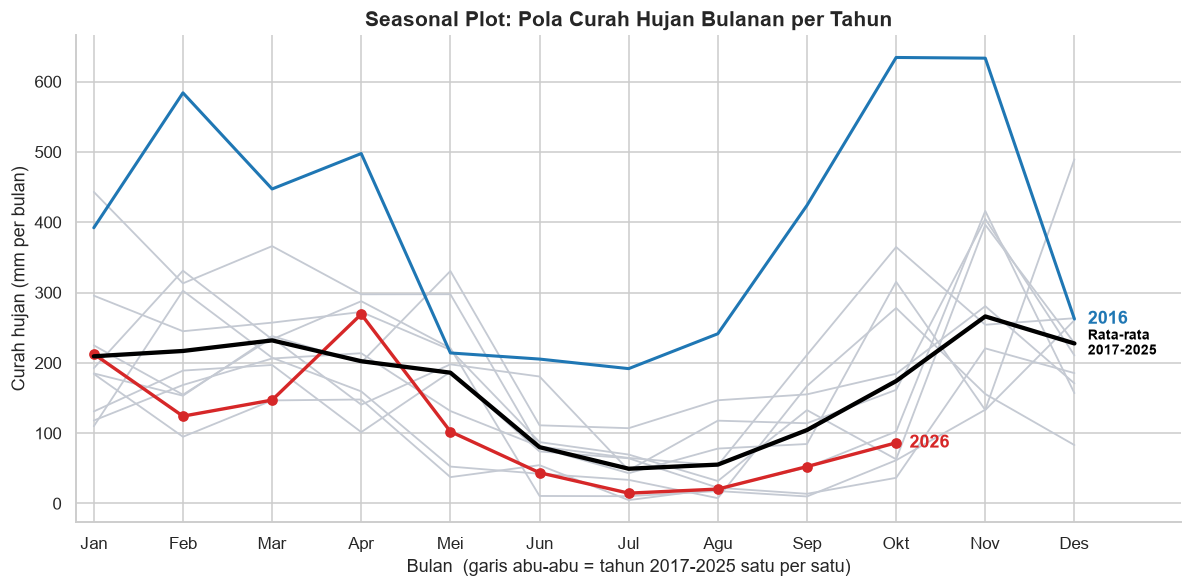

In [23]:
pivot_hujan = bulanan.pivot(index="tahun", columns="bulan", values="hujan")

fig, ax = plt.subplots(figsize=(11, 5.5))
for thn in pivot_hujan.index:
    if thn in (2016, 2026):
        continue
    ax.plot(range(1, 13), pivot_hujan.loc[thn], color="#c5cad3", lw=1.2)

ax.plot(range(1, 13), pivot_hujan.loc[2016], color="#1f77b4", lw=2, label="2016")
ax.plot(range(1, 13), pivot_hujan.loc[2026], color="#d62728", lw=2.2, marker="o", label="2026 (hingga Okt)")
ax.plot(range(1, 13), pivot_hujan.drop(index=[2016, 2026]).mean(), color="black", lw=2.8,
        label="Rata-rata 2017-2025")

ax.text(12.15, pivot_hujan.loc[2016, 12], "2016", color="#1f77b4", va="center", fontweight="bold")
ax.text(10.15, pivot_hujan.loc[2026, 10], "2026", color="#d62728", va="center", fontweight="bold")
ax.text(12.15, pivot_hujan.drop(index=[2016, 2026]).mean()[12], "Rata-rata\n2017-2025", color="black",
        va="center", fontweight="bold", fontsize=9)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(NAMA_BULAN)
ax.set_xlim(0.8, 13.2)
ax.set_title("Seasonal Plot: Pola Curah Hujan Bulanan per Tahun")
ax.set_xlabel("Bulan  (garis abu-abu = tahun 2017-2025 satu per satu)")
ax.set_ylabel("Curah hujan (mm per bulan)")
plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Seasonal plot menumpuk tiap tahun pada sumbu bulan yang sama (Jan–Des), sehingga **pola musiman** dan tahun yang 'menyimpang' langsung kelihatan.
>
> **Ngapain di cell ini?** Membuat tabel bulan × tahun untuk total hujan, menggambar 2017–2025 sebagai garis abu-abu, lalu menyorot tahun 2016 (biru), 2026 (merah), dan rata-rata 2017–2025 (hitam tebal) dengan label langsung.
>
> **Insight / hasilnya:** Pola musim **konsisten**: garis rata-rata (hitam) tinggi di Nov–Mei (kira-kira 185–265 mm per bulan, puncak November), lalu turun tajam ke titik terendah di **Juli–Agustus (di bawah 100 mm)**, dan naik lagi mulai September. Tahun **2016 (biru)** jauh di atas semua tahun lain, hampir sepanjang tahun (anomali basah). Tahun **2026 (merah) cenderung di bawah rata-rata** hampir sepanjang tahun, kecuali Januari (setara rata-rata) dan April (±269 mm, lebih basah dari biasanya).

### 4.5 Calendar Heatmap (Tahun × Bulan) — pola suhu

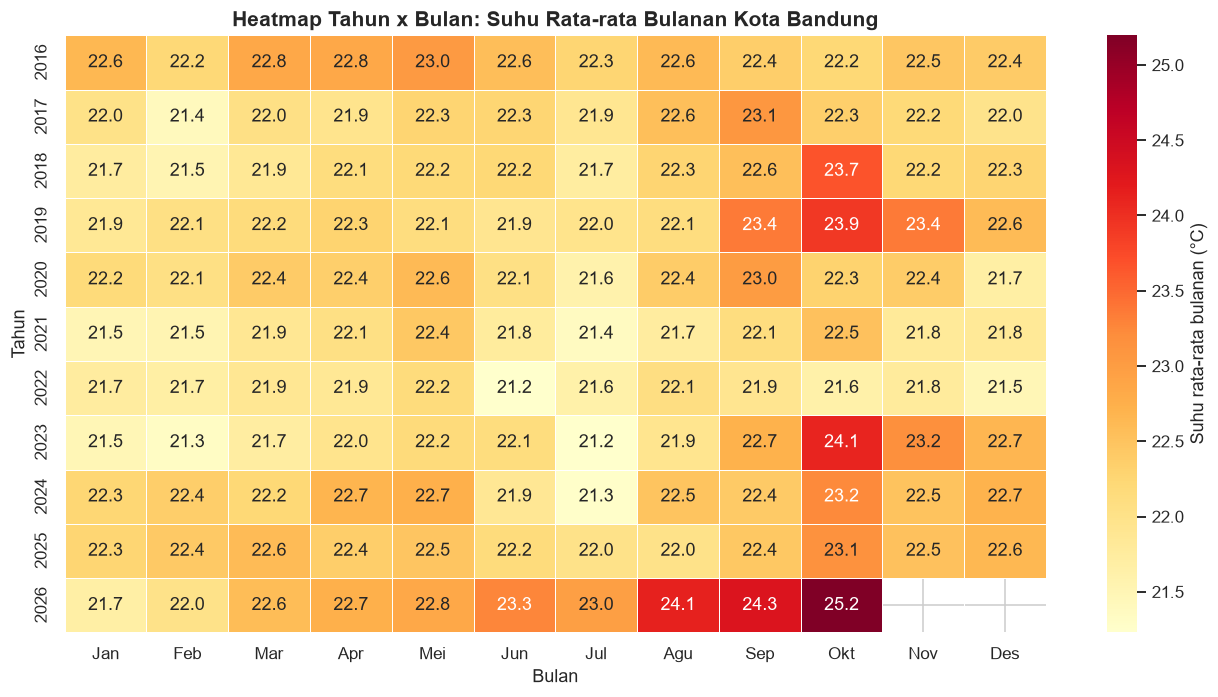

In [24]:
pivot_suhu = bulanan.pivot(index="tahun", columns="bulan", values="suhu_rata")
pivot_suhu.columns = NAMA_BULAN

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(pivot_suhu, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Suhu rata-rata bulanan (°C)"}, ax=ax)
ax.set_title("Heatmap Tahun x Bulan: Suhu Rata-rata Bulanan Kota Bandung")
ax.set_xlabel("Bulan")
ax.set_ylabel("Tahun")
plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Heatmap memadatkan banyak angka menjadi peta warna: baris = tahun, kolom = bulan, warna = suhu rata-rata bulanan. Bagus untuk melihat pola musiman sekaligus bulan/tahun yang tidak biasa tanpa membaca angka satu per satu.
>
> **Ngapain di cell ini?** Menyusun suhu rata-rata bulanan menjadi tabel tahun × bulan, lalu menampilkannya dengan `sns.heatmap` (makin gelap/merah = makin panas) lengkap dengan angka di tiap kotak. Kotak Nov–Des 2026 kosong karena datanya belum ada.
>
> **Insight / hasilnya:** Warna paling panas selalu muncul di **kolom Agustus–Oktober** (akhir kemarau), dan paling sejuk di Juni–Juli. Kotak terpanas seluruh data adalah **Oktober 2026 (25,2 °C)**, diikuti Sep 2026 (24,3), Agu 2026 (24,1), Okt 2023 (24,1), dan Okt 2019 (23,9). Artinya **Juni–Oktober 2026 secara konsisten jauh lebih hangat dari biasanya** (sekitar 1–2 °C di atas rata-rata bulan yang sama). Penyebabnya tidak bisa dipastikan dari dataset ini; kejadian serupa (2019, 2023) bisa jadi terkait fenomena iklim seperti El Niño, tetapi itu masih dugaan yang perlu dicek ke sumber lain.

## 5. Analisis Tren

### 5.1 Moving Average (window 7, 30, dan 90 hari)

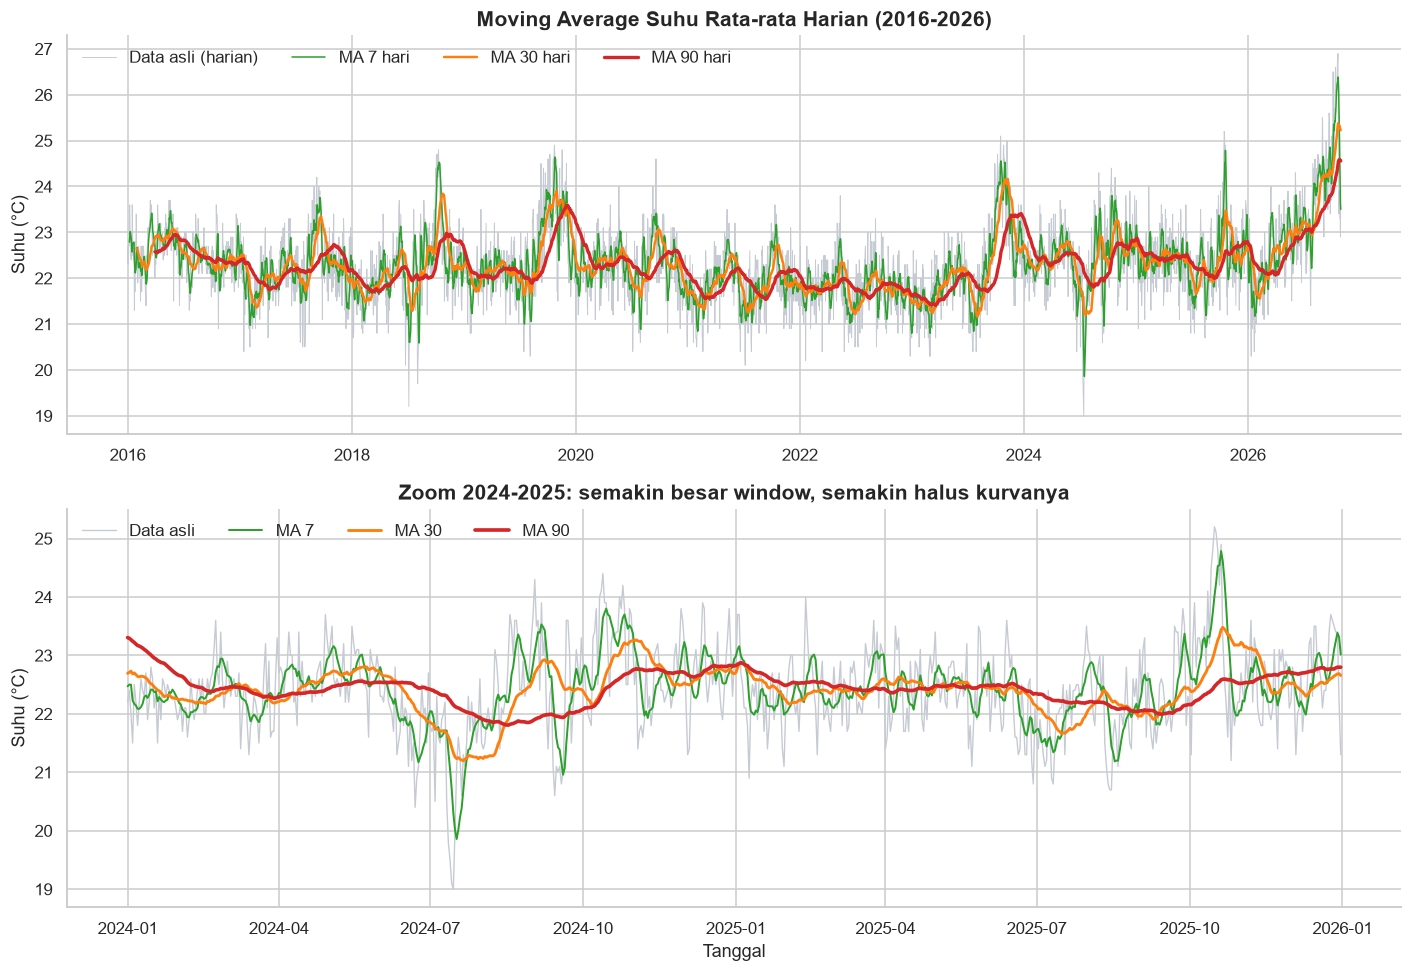

In [25]:
s = df["suhu_rata"]
ma7 = s.rolling(window=7).mean()
ma30 = s.rolling(window=30).mean()
ma90 = s.rolling(window=90).mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Panel atas: seluruh periode
ax = axes[0]
ax.plot(s, color="#c5cad3", lw=0.6, label="Data asli (harian)")
ax.plot(ma7, color="#2ca02c", lw=1.0, label="MA 7 hari")
ax.plot(ma30, color="#ff7f0e", lw=1.6, label="MA 30 hari")
ax.plot(ma90, color="#d62728", lw=2.2, label="MA 90 hari")
ax.set_title("Moving Average Suhu Rata-rata Harian (2016-2026)")
ax.set_ylabel("Suhu (°C)")
ax.legend(loc="upper left", ncol=4, frameon=False)

# Panel bawah: zoom 2 tahun agar efek window terlihat jelas
ax = axes[1]
z = slice("2024-01-01", "2025-12-31")
ax.plot(s[z], color="#c5cad3", lw=0.9, label="Data asli")
ax.plot(ma7[z], color="#2ca02c", lw=1.3, label="MA 7")
ax.plot(ma30[z], color="#ff7f0e", lw=1.9, label="MA 30")
ax.plot(ma90[z], color="#d62728", lw=2.4, label="MA 90")
ax.set_title("Zoom 2024-2025: semakin besar window, semakin halus kurvanya")
ax.set_ylabel("Suhu (°C)")
ax.set_xlabel("Tanggal")
ax.legend(loc="upper left", ncol=4, frameon=False)

plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Data harian penuh 'noise' (naik-turun acak), sehingga tren sulit terlihat. *Moving average* (rata-rata bergerak) menghaluskan data dengan merata-ratakan beberapa hari terakhir.
>
> **Ngapain di cell ini?** Menghitung moving average dengan tiga ukuran window (7, 30, 90 hari) pada suhu rata-rata harian, lalu menimpanya di atas data asli. Panel atas menampilkan seluruh periode, panel bawah memperbesar tahun 2024–2025 agar perbedaan kehalusannya jelas.
>
> **Insight / hasilnya:** **Makin besar window, makin halus kurvanya.** MA 7 hari (hijau) masih cukup bergerigi tapi sudah membuang gerigi harian; MA 30 hari (oranye) memperlihatkan naik-turun musiman bulan-ke-bulan; MA 90 hari (merah) hampir berupa kurva mulus yang hanya menunjukkan pergerakan besar. MA 90 hari paling jelas memperlihatkan **kenaikan suhu di akhir 2026**.

### 5.2 Trade-off ukuran window

In [26]:
tabel = pd.DataFrame({"Data asli": s, "MA 7": ma7, "MA 30": ma30, "MA 90": ma90})

ringkas = pd.DataFrame({
    "Data kosong (NaN) di awal": tabel.isna().sum(),
    "Naik-turun harian (std selisih)": tabel.diff().std().round(3),
    "Rentang nilai (max - min, °C)": (tabel.max() - tabel.min()).round(2),
})
print("Trade-off ukuran window moving average:")
ringkas

Trade-off ukuran window moving average:


,Data kosong (NaN) di awal,Naik-turun harian (std selisih),"Rentang nilai (max - min, °C)"
Data asli,0,0.561,7.90
MA 7,6,0.119,6.53
MA 30,29,0.032,4.22
MA 90,89,0.013,3.18


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Tugas meminta kita menjelaskan harga yang harus dibayar untuk kurva yang lebih halus. Tabel ini mengukurnya dengan angka, bukan hanya kesan visual.
>
> **Ngapain di cell ini?** Membandingkan data asli dengan MA 7, 30, 90 dari tiga sisi: berapa banyak data kosong (NaN) di awal, seberapa besar naik-turun dari hari ke hari (std selisih harian; makin kecil = makin halus), dan rentang nilai (maks − min).
>
> **Insight / hasilnya:** **Kehalusan naik, tapi data awal hilang.** Naik-turun harian turun dari 0,561 (data asli) → 0,119 (MA 7) → 0,032 (MA 30) → 0,013 (MA 90). Namun harga yang dibayar: MA 7 kehilangan 6 hari pertama, MA 30 kehilangan 29 hari, MA 90 kehilangan 89 hari (NaN). Rentang nilai juga menyusut (7,90 → 3,18 °C), artinya puncak dan lembah ekstrem ikut 'terpotong'. Window besar juga bereaksi lebih lambat terhadap perubahan mendadak. Kesimpulannya, window 30 hari adalah kompromi yang baik: cukup halus tapi masih menyimpan pola musiman.

### 5.3 Fitting model matematika (linear & polinomial) pada suhu rata-rata bulanan

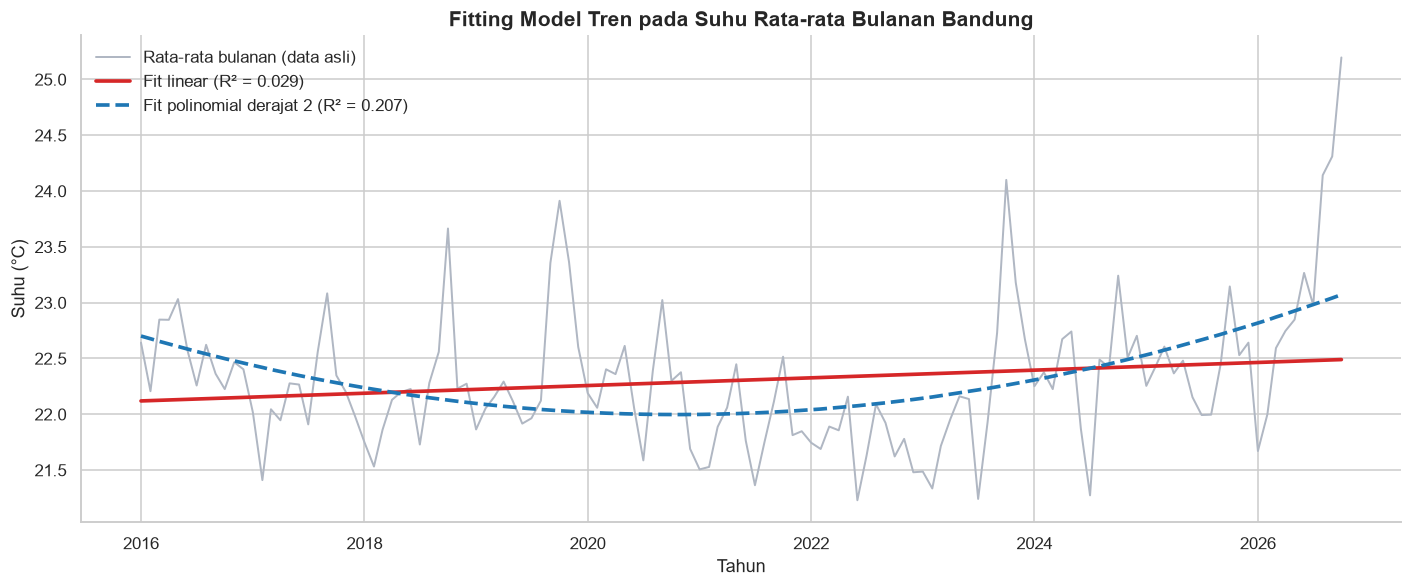

Kemiringan linear : 0.00287 °C/bulan  ->  +0.34 °C per dekade
Total perubahan   : +0.37 °C selama 130 bulan


In [27]:
bln = bulanan["suhu_rata"]
x = np.arange(len(bln))   # 0 = Jan 2016, 1 = Feb 2016, dst.

def fit_poly(y, derajat):
    koef = np.polyfit(x, y.values, derajat)
    prediksi = np.polyval(koef, x)
    r2 = 1 - ((y.values - prediksi) ** 2).sum() / ((y.values - y.values.mean()) ** 2).sum()
    return koef, prediksi, r2

koef1, linear, r2_1 = fit_poly(bln, 1)
koef2, kuadrat, r2_2 = fit_poly(bln, 2)

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(bln.index, bln.values, color="#b0b7c3", lw=1.3, label="Rata-rata bulanan (data asli)")
ax.plot(bln.index, linear, color="#d62728", lw=2.4, label=f"Fit linear (R² = {r2_1:.3f})")
ax.plot(bln.index, kuadrat, color="#1f77b4", lw=2.4, ls="--", label=f"Fit polinomial derajat 2 (R² = {r2_2:.3f})")
ax.set_title("Fitting Model Tren pada Suhu Rata-rata Bulanan Bandung")
ax.set_xlabel("Tahun")
ax.set_ylabel("Suhu (°C)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

print(f"Kemiringan linear : {koef1[0]:.5f} °C/bulan  ->  {koef1[0] * 120:+.2f} °C per dekade")
print(f"Total perubahan   : {linear[-1] - linear[0]:+.2f} °C selama {len(bln)} bulan")

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Selain menghaluskan, kita bisa mencocokkan *garis/kurva tren* dengan rumus matematika menggunakan `numpy.polyfit` untuk mengetahui arah dan besarnya perubahan jangka panjang.
>
> **Ngapain di cell ini?** Mengubah waktu menjadi urutan angka bulan (0, 1, 2, …), lalu mencocokkan garis lurus (derajat 1) dan kurva lengkung (derajat 2) ke suhu rata-rata bulanan. Nilai R² dihitung untuk melihat seberapa baik model menjelaskan data.
>
> **Insight / hasilnya:** Garis linear naik tipis: **+0,34 °C per dekade** (total sekitar +0,37 °C selama 130 bulan). Tetapi **R² linear hanya 0,029**, artinya garis ini hanya menjelaskan ±3% variasi suhu, jadi tren naiknya lemah dibanding variasi musiman dan antar-tahun. Kurva derajat 2 (R² 0,207) lebih cocok: suhu cenderung **turun sampai sekitar 2020–2021 lalu naik lagi**, terutama karena lonjakan 2026. Kesimpulan hati-hati: ada kecenderungan naik, tetapi belum bisa disebut tren jangka panjang yang kuat.

### 5.4 Fit linear untuk suhu maksimum, rata-rata, dan minimum

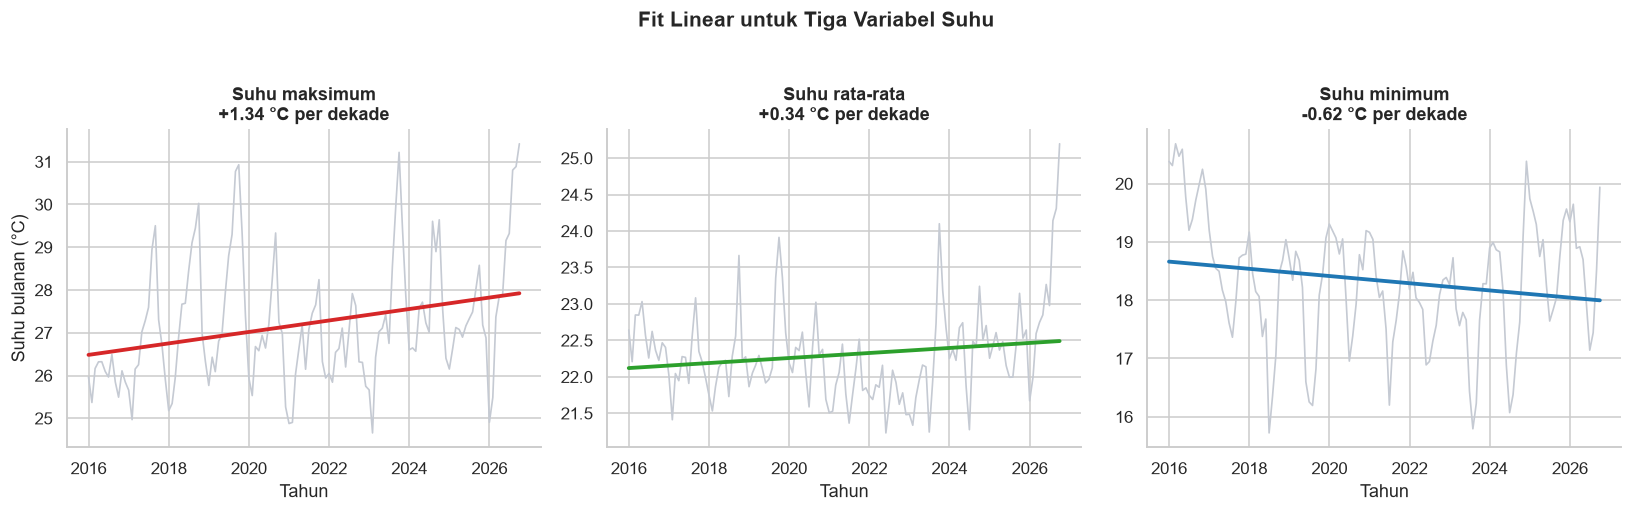

In [28]:
variabel = {"suhu_maks": "Suhu maksimum", "suhu_rata": "Suhu rata-rata", "suhu_min": "Suhu minimum"}
warna = {"suhu_maks": "#d62728", "suhu_rata": "#2ca02c", "suhu_min": "#1f77b4"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (kol, nama) in zip(axes, variabel.items()):
    y = bulanan[kol]
    koef = np.polyfit(x, y.values, 1)
    garis = np.polyval(koef, x)
    ax.plot(y.index, y.values, color="#c5cad3", lw=1.1)
    ax.plot(y.index, garis, color=warna[kol], lw=2.5)
    ax.set_title(f"{nama}\n{koef[0] * 120:+.2f} °C per dekade", fontsize=12)
    ax.set_xlabel("Tahun")
ax.figure.suptitle("Fit Linear untuk Tiga Variabel Suhu", fontsize=14, fontweight="bold", y=1.03)
axes[0].set_ylabel("Suhu bulanan (°C)")
plt.tight_layout()
plt.show()

> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Mengecek apakah tren berbeda untuk suhu siang (maksimum), rata-rata, dan malam (minimum).
>
> **Ngapain di cell ini?** Menghitung garis linear untuk masing-masing variabel dan menampilkan kemiringannya dalam °C per dekade pada judul tiap panel.
>
> **Insight / hasilnya:** Hasil yang berlawanan arah: suhu maksimum **naik** (+1,34 °C/dekade), rata-rata naik tipis (+0,34), sedangkan suhu minimum **turun** (−0,62). Ini artinya selisih siang–malam melebar. Namun hasil ini perlu dicek lagi (lihat cell berikutnya), karena awal data (2016) tampak punya suhu minimum yang tinggi.

### 5.5 Uji sensitivitas: apakah hasil tren bergantung pada tahun 2016?

In [29]:
# Uji sensitivitas: apakah kemiringan tren berubah kalau 2016 (tahun yang tidak biasa) dibuang?
hasil = {}
for nama, mulai in [("Seluruh periode (Jan 2016 - Okt 2026)", "2016-01-01"), ("Mulai Jan 2017", "2017-01-01")]:
    sub = bulanan.loc[mulai:]
    xs = np.arange(len(sub))
    hasil[nama] = {
        "Suhu maks (°C/dekade)": np.polyfit(xs, sub["suhu_maks"], 1)[0] * 120,
        "Suhu rata-rata (°C/dekade)": np.polyfit(xs, sub["suhu_rata"], 1)[0] * 120,
        "Suhu min (°C/dekade)": np.polyfit(xs, sub["suhu_min"], 1)[0] * 120,
    }
pd.DataFrame(hasil).T.round(2)

,Suhu maks (°C/dekade),Suhu rata-rata (°C/dekade),Suhu min (°C/dekade)
Seluruh periode (Jan 2016 - Okt 2026),1.34,0.34,-0.62
Mulai Jan 2017,0.97,0.63,0.36


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Memastikan kesimpulan tren tidak sekadar akibat satu tahun awal yang tidak biasa. Ini cara sederhana menguji apakah tren itu kokoh.
>
> **Ngapain di cell ini?** Menghitung ulang kemiringan tren dua kali: memakai semua data, dan memakai data mulai Januari 2017 (tanpa 2016).
>
> **Insight / hasilnya:** Hasilnya berubah cukup besar, terutama suhu minimum: dari **−0,62** menjadi **+0,36 °C/dekade** (rata-rata dari +0,34 menjadi +0,63; maksimum dari +1,34 menjadi +0,97). Jadi tanda 'suhu minimum turun' hanya muncul karena 2016 yang tinggi di awal. Pelajarannya: **tren dari rentang data yang pendek (±11 tahun) sangat sensitif** terhadap titik awal, sehingga angka °C/dekade sebaiknya dibaca sebagai indikasi, bukan kepastian.

## 6. Ringkasan Insight

In [30]:
tahunan = df[df.index.year < 2026].groupby(df[df.index.year < 2026].index.year).agg(
    suhu_rata=("suhu_rata", "mean"), hujan_total=("hujan", "sum"), sinar_jam=("sinar_jam", "mean")).round(2)
print("Ringkasan tahunan (2026 tidak ditampilkan karena baru sampai Oktober):")
display(tahunan)

print("\n--- Rekor dalam data ---")
print(f"Hari terpanas (suhu maks)  : {df['suhu_maks'].idxmax():%d %b %Y} -> {df['suhu_maks'].max():.1f} °C")
print(f"Malam terdingin (suhu min) : {df['suhu_min'].idxmin():%d %b %Y} -> {df['suhu_min'].min():.1f} °C")
print(f"Hujan harian terderas      : {df['hujan'].idxmax():%d %b %Y} -> {df['hujan'].max():.1f} mm")
print(f"Bulan terbasah             : {bulanan['hujan'].idxmax():%b %Y} -> {bulanan['hujan'].max():.0f} mm")
print(f"Bulan terkering            : {bulanan['hujan'].idxmin():%b %Y} -> {bulanan['hujan'].min():.1f} mm")
print(f"Persentase hari hujan (>=1 mm): {(df['hujan'] >= 1).mean() * 100:.0f}%")
print(f"Jumlah hari hujan lebat (>=20 mm): {(df['hujan'] >= 20).sum()} hari")

print("\nKorelasi antar variabel harian:")
korelasi = df[["suhu_rata", "suhu_maks", "suhu_min", "hujan", "sinar_jam", "angin_maks"]].corr().round(2)
korelasi

Ringkasan tahunan (2026 tidak ditampilkan karena baru sampai Oktober):


,suhu_rata,hujan_total,sinar_jam
tanggal,,,
2016,22.54,4727.8,8.51
2017,22.17,1599.2,9.53
2018,22.21,1418.1,9.74
2019,22.48,1998.8,9.99
2020,22.25,2711.3,9.17
2021,21.89,2190.1,9.05
2022,21.76,2131.7,8.98
2023,22.22,1422.6,9.89
2024,22.40,2297.8,9.68



--- Rekor dalam data ---
Hari terpanas (suhu maks)  : 14 Oct 2026 -> 34.2 °C
Malam terdingin (suhu min) : 26 Jul 2021 -> 12.9 °C
Hujan harian terderas      : 25 Feb 2017 -> 96.7 mm
Bulan terbasah             : Oct 2016 -> 634 mm
Bulan terkering            : Jul 2018 -> 4.8 mm
Persentase hari hujan (>=1 mm): 64%
Jumlah hari hujan lebat (>=20 mm): 315 hari

Korelasi antar variabel harian:


,suhu_rata,suhu_maks,suhu_min,hujan,sinar_jam,angin_maks
suhu_rata,1.00,0.71,0.25,-0.19,0.40,-0.16
suhu_maks,0.71,1.00,-0.38,-0.33,0.67,-0.03
suhu_min,0.25,-0.38,1.00,0.36,-0.49,-0.13
hujan,-0.19,-0.33,0.36,1.00,-0.44,-0.23
sinar_jam,0.40,0.67,-0.49,-0.44,1.00,0.01
angin_maks,-0.16,-0.03,-0.13,-0.23,0.01,1.00


> ### 💡 Penjelasan cell di atas
>
> **Untuk apa?** Mengumpulkan angka-angka kunci (rekor, rata-rata tahunan, korelasi antar variabel) untuk dijadikan bahan kesimpulan dan laporan.
>
> **Ngapain di cell ini?** Menghitung ringkasan tahunan (2026 dikeluarkan karena belum setahun penuh), rekor suhu dan hujan, persentase hari hujan, dan tabel korelasi antar variabel harian.
>
> **Insight / hasilnya:** **Rekor:** hari terpanas 14 Okt 2026 (maks 34,2 °C), malam terdingin 26 Jul 2021 (12,9 °C), hujan harian terderas 25 Feb 2017 (96,7 mm). **Hujan:** 64% hari dalam data memiliki hujan ≥1 mm dan ada 315 hari hujan lebat (≥20 mm). **Tahunan:** suhu rata-rata tahunan hanya berkisar 21,8–22,5 °C; 2021–2022 paling sejuk, 2016 paling hangat; hujan tahunan 1.418 mm (2018) sampai 4.728 mm (2016). **Korelasi:** suhu maksimum berkorelasi kuat dengan lama sinar matahari (+0,67), hujan berkorelasi negatif dengan sinar matahari (−0,44) dan suhu maksimum (−0,33), sedangkan suhu minimum justru sedikit naik saat hujan (+0,36) karena awan menahan panas malam hari. Kecepatan angin hampir tidak berhubungan dengan variabel lain.

## 7. Kesimpulan

### Insight kunci
1. **Suhu Bandung sangat stabil.** Suhu rata-rata harian hampir selalu berada di 21,5–23 °C (rata-rata 22,3 °C, std 0,86 °C) karena letaknya di dataran tinggi.
2. **Ada dua musim yang jelas.** Musim hujan Nov–Mar (November rata-rata terbasah, ±303 mm) dan kemarau Jun–Agu (Juli rata-rata terkering, ±59 mm). Pola ini berulang hampir setiap tahun (seasonal plot).
3. **Kemarau = siang panas, malam dingin.** Saat kemarau, langit cerah (sinar matahari hingga 11,4 jam/hari), suhu maksimum naik ke ±28–29 °C dan suhu minimum turun ke ±17 °C. Hujan dan awan membuat siang lebih sejuk tetapi malam lebih hangat (korelasi hujan–suhu minimum +0,36).
4. **Ada tahun dan bulan yang tidak biasa.** 2016 sangat basah (±4.728 mm; Oktober 2016 = 634 mm), 2017–2018 kemarau sangat kering (Juli 2018 hanya 4,8 mm), dan **Juni–Oktober 2026 jauh lebih hangat dari biasanya** dengan rekor Oktober 2026 (rata-rata 25,2 °C; suhu maksimum harian 34,2 °C).
5. **Moving average: makin besar window, makin halus, tapi makin banyak data awal hilang** (6, 29, 89 hari untuk window 7, 30, 90) dan puncak ekstrem terpotong. Window 30 hari adalah kompromi terbaik.
6. **Tren jangka panjang lemah dan sensitif.** Fit linear suhu rata-rata menunjukkan +0,34 °C/dekade tetapi R² hanya 0,029. Uji sensitivitas memperlihatkan hasil berubah drastis (suhu minimum dari −0,62 jadi +0,36 °C/dekade) jika 2016 dibuang, jadi kesimpulan tren harus disampaikan dengan hati-hati.

### Kendala yang dihadapi
- File CSV memiliki baris metadata di bagian atas sehingga perlu penanganan khusus saat dibaca.
- Rentang data hanya ±11 tahun, terlalu pendek untuk menyimpulkan tren iklim; hasil tren sangat dipengaruhi tahun awal (2016) dan tahun akhir (2026).
- Tahun 2026 baru sampai Oktober, sehingga tidak bisa dibandingkan langsung dengan tahun penuh.
- Data berasal dari model/reanalisis cuaca pada satu titik koordinat, bukan hasil ukur satu stasiun fisik, sehingga bisa berbeda dari catatan BMKG di lapangan.
- Dataset tidak punya variabel penjelas (mis. indeks El Niño/La Niña), jadi penyebab anomali hanya bisa diduga, bukan dibuktikan.

### Yang ingin ditambahkan jika ada waktu lebih
- Membandingkan dengan data stasiun BMKG Bandung untuk memvalidasi dataset.
- Menambahkan indeks iklim (ENSO/ONI) untuk menjelaskan tahun basah/panas.
- Dekomposisi time series (tren + musiman + residu) dan uji statistik tren (mis. Mann–Kendall).
- Membandingkan Bandung dengan kota lain (mis. Jakarta atau Surabaya).
- Membuat dashboard interaktif (Plotly/Streamlit) untuk Final Project.

## 9. Daftar Pustaka

- Open-Meteo. *Historical Weather API*. https://open-meteo.com/en/docs/historical-weather-api (diakses sesuai tanggal unduh data oleh kelompok).
- Dataset: `Dataset_Bandung_jan_2016_-_sep_2026.csv` (cuaca harian Kota Bandung, 1 Jan 2016 – 31 Okt 2026).
- Dokumentasi pandas: https://pandas.pydata.org/docs/
- Dokumentasi matplotlib: https://matplotlib.org/stable/
- Dokumentasi seaborn: https://seaborn.pydata.org/
- Dokumentasi numpy `polyfit`: https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html
- Materi kuliah CAK4XBB3 Visualisasi Data, Minggu 6 (Visualisasi Data Time Series).